<a href="https://colab.research.google.com/github/BHAGI-99/CS5998-Capstone-Project-P.B.W.Nanayakkara-268472T/blob/main/notebooks/02_explainability_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!git clone https://github.com/BHAGI-99/CS5998-Capstone-Project-P.B.W.Nanayakkara-268472T.git project
%cd project
!python src/download_data.py
!python src/segment.py

Cloning into 'project'...
remote: Enumerating objects: 56, done.
remote: Counting objects: 100% (56/56), done.
remote: Compressing objects: 100% (51/51), done.
remote: Total 56 (delta 17), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (56/56), 983.01 KiB | 2.95 MiB/s, done.
Resolving deltas: 100% (17/17), done.
/content/project/project
Cloning into 'data/raw/Smart-Sleeve-Dataset'...
remote: Enumerating objects: 445, done.
remote: Counting objects: 100% (445/445), done.
remote: Compressing objects: 100% (318/318), done.
remote: Total 445 (delta 127), reused 443 (delta 127), pack-reused 0 (from 0)
Receiving objects: 100% (445/445), 87.33 MiB | 13.16 MiB/s, done.
Resolving deltas: 100% (127/127), done.
Updating files: 100% (287/287), done.
Done. Data folder: data/raw/Smart-Sleeve-Dataset/Smart-Sleeve Dataset
X (2520, 208, 200) uint16 | classes: 18 | subjects: 14
truncated segments: 123


In [3]:
import tensorflow as tf
print(tf.__version__)

2.21.0


X (2520, 208, 200) | pressure min/max: 0 4014


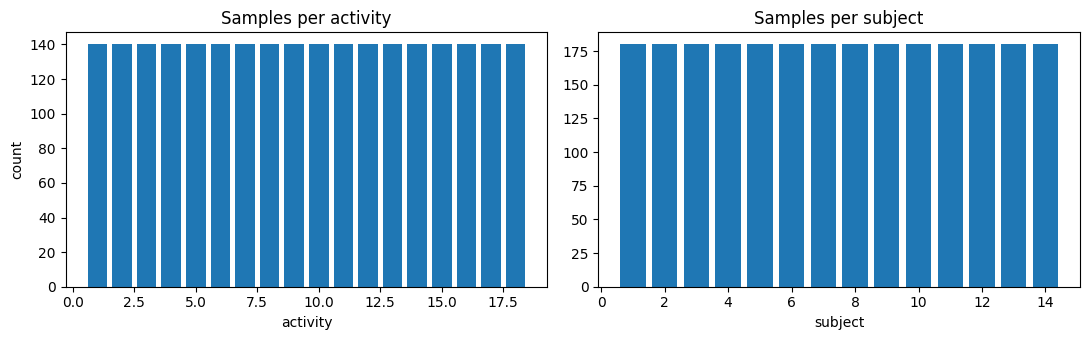

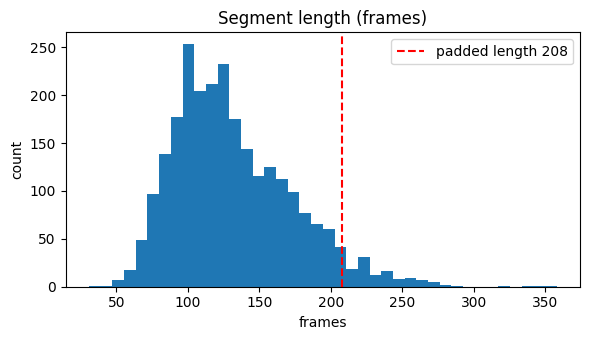

median length 124.0 | truncated: 123


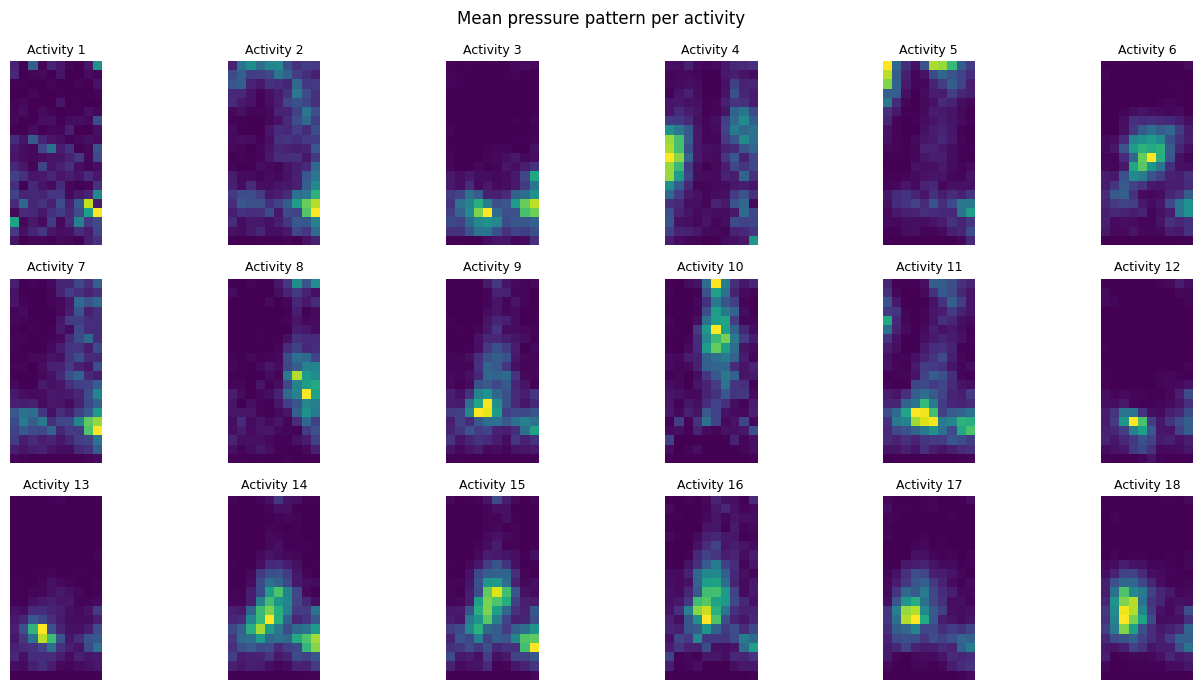

avg change over time: 3.6 | avg pressure: 27.1 | ratio: 0.13


In [4]:
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
P = Path("data/processed"); F = Path("results/figures"); F.mkdir(parents=True, exist_ok=True)
X = np.load(P/"X.npy"); y = np.load(P/"y.npy"); subj = np.load(P/"subject.npy"); lens = np.load(P/"lengths.npy")
print("X", X.shape, "| pressure min/max:", X.min(), X.max())

# 1. balance of activities and subjects
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(np.arange(1,19), np.bincount(y)); ax[0].set(title="Samples per activity", xlabel="activity", ylabel="count")
ax[1].bar(np.arange(1,15), np.bincount(subj)[1:]); ax[1].set(title="Samples per subject", xlabel="subject")
plt.tight_layout(); plt.savefig(F/"eda_balance.png", dpi=120); plt.show()

# 2. segment lengths
fig, ax = plt.subplots(figsize=(6,3.5))
ax.hist(lens, bins=40); ax.axvline(208, color="r", ls="--", label="padded length 208")
ax.set(title="Segment length (frames)", xlabel="frames", ylabel="count"); ax.legend()
plt.tight_layout(); plt.savefig(F/"eda_lengths.png", dpi=120); plt.show()
print("median length", np.median(lens), "| truncated:", (lens>208).sum())

# 3. average pressure pattern for each activity (20 x 10 sensor grid)
fig, axes = plt.subplots(3, 6, figsize=(14, 7))
for c, ax in enumerate(axes.ravel()):
    m = np.array([X[i,:min(lens[i],208)].mean(axis=0) for i in np.where(y==c)[0]]).mean(axis=0).reshape(20,10)
    ax.imshow(m, cmap="viridis"); ax.set_title(f"Activity {c+1}", fontsize=9); ax.axis("off")
plt.suptitle("Mean pressure pattern per activity")
plt.tight_layout(); plt.savefig(F/"eda_activity_heatmaps.png", dpi=120); plt.show()

# 4. how much does pressure change over time inside a segment?
sd = np.array([X[i,:min(lens[i],208)].astype(float).std(axis=0).mean() for i in range(len(X))])
mp = np.array([X[i,:min(lens[i],208)].astype(float).mean() for i in range(len(X))])
print("avg change over time: %.1f | avg pressure: %.1f | ratio: %.2f" % (sd.mean(), mp.mean(), sd.mean()/mp.mean()))

In [5]:
import numpy as np, pandas as pd, time
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

SEED = 42; P = Path("data/processed")
X = np.load(P/"X.npy"); y = np.load(P/"y.npy"); subj = np.load(P/"subject.npy"); lens = np.load(P/"lengths.npy")

# Summary features from the real (unpadded) frames: mean, std and max of each of the 200 sensors
feats = []
for i in range(len(X)):
    seg = X[i, :min(lens[i], X.shape[1])].astype(np.float32) / 4095.0   # sensor range is 0-4095
    feats.append(np.concatenate([seg.mean(0), seg.std(0), seg.max(0)]))
F = np.array(feats); print("feature table:", F.shape)

models = {
  "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
  "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}
cv10 = StratifiedKFold(10, shuffle=True, random_state=SEED)
rows = []
for name, m in models.items():
    for proto, cv, groups in [("10-fold", cv10, None), ("LOSO", LeaveOneGroupOut(), subj)]:
        t = time.time()
        p = cross_val_predict(m, F, y, cv=cv, groups=groups)
        acc, f1 = accuracy_score(y, p), f1_score(y, p, average="macro")
        rows.append([name, proto, round(acc, 4), round(f1, 4)])
        print(f"{name:20s} {proto:8s} acc={acc:.4f}  macroF1={f1:.4f}  ({time.time()-t:.0f}s)")
Path("results").mkdir(exist_ok=True)
pd.DataFrame(rows, columns=["model", "protocol", "accuracy", "macro_f1"]).to_csv("results/baselines.csv", index=False)

feature table: (2520, 600)
Logistic Regression  10-fold  acc=0.6861  macroF1=0.6867  (31s)
Logistic Regression  LOSO     acc=0.5933  macroF1=0.5931  (53s)
Random Forest        10-fold  acc=0.7433  macroF1=0.7398  (38s)
Random Forest        LOSO     acc=0.6651  macroF1=0.6600  (53s)


In [6]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, tensorflow as tf, time
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score
from tensorflow.keras import layers

SEED = 42
def set_seed(s=SEED):
    np.random.seed(s); tf.random.set_seed(s); tf.keras.utils.set_random_seed(s)
set_seed()
P = Path("data/processed")
X = np.load(P/"X.npy").astype(np.float32) / 4095.0      # sensor range is 0-4095
y = np.load(P/"y.npy")

def build_cnn(seq_len=208, n_feat=200, n_classes=18):
    inp = tf.keras.Input(shape=(seq_len, n_feat))
    x = layers.Conv1D(64, 5, padding="same")(inp);  x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 5, padding="same")(x);   x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 3, padding="same", name="last_conv")(x); x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling1D()(x)               # needed later for CAM
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = tf.keras.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def train_predict(tr, te, max_epochs=60):
    set_seed()
    tr_in, va = train_test_split(tr, test_size=0.1, stratify=y[tr], random_state=SEED)   # validation comes from the training part only
    m = build_cnn()
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    h = m.fit(X[tr_in], y[tr_in], validation_data=(X[va], y[va]), epochs=max_epochs, batch_size=32, callbacks=[es], verbose=0)
    return m.predict(X[te], verbose=0).argmax(1), len(h.history["loss"])

cv = StratifiedKFold(10, shuffle=True, random_state=SEED)
preds = np.zeros(len(y), dtype=int); rows = []
for k, (tr, te) in enumerate(cv.split(X, y), 1):
    t = time.time()
    p, ep = train_predict(tr, te); preds[te] = p
    acc = accuracy_score(y[te], p); rows.append([k, acc, ep])
    print(f"fold {k:2d}: acc={acc:.4f}  epochs={ep}  ({time.time()-t:.0f}s)")

print(f"\nCNN 10-fold: acc={accuracy_score(y, preds):.4f}  macroF1={f1_score(y, preds, average='macro'):.4f}")
Path("results").mkdir(exist_ok=True)
pd.DataFrame(rows, columns=["fold", "accuracy", "epochs"]).to_csv("results/cnn_10fold_folds.csv", index=False)
np.save("results/cnn_10fold_preds.npy", preds)

fold  1: acc=0.7460  epochs=20  (36s)
fold  2: acc=0.6944  epochs=19  (19s)


fold  3: acc=0.7778  epochs=23  (22s)


fold  4: acc=0.7103  epochs=19  (19s)
fold  5: acc=0.7103  epochs=19  (19s)
fold  6: acc=0.7738  epochs=23  (22s)
fold  7: acc=0.7659  epochs=19  (19s)
fold  8: acc=0.7659  epochs=24  (22s)
fold  9: acc=0.7857  epochs=27  (24s)
fold 10: acc=0.7460  epochs=23  (22s)

CNN 10-fold: acc=0.7476  macroF1=0.7471


In [7]:
import os
if not os.path.exists("/content/project"):
    !git clone https://github.com/BHAGI-99/CS5998-Capstone-Project-P.B.W.Nanayakkara-268472T.git /content/project
%cd /content/project
if not os.path.exists("data/processed/X.npy"):
    !python src/download_data.py
    !python src/segment.py

/content/project


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
held-out subject  1: acc=0.6889  epochs=21  (32s)
held-out subject  2: acc=0.6000  epochs=24  (22s)
held-out subject  3: acc=0.7056  epochs=28  (24s)
held-out subject  4: acc=0.5833  epochs=18  (19s)
held-out subject  5: acc=0.6667  epochs=23  (22s)
held-out subject  6: acc=0.5500  epochs=23  (22s)
held-out subject  7: acc=0.7444  epochs=22  (21s)
held-out subject  8: acc=0.6111  epochs=20  (21s)
held-out subject  9: acc=0.7444  epochs=24  (22s)
held-out subject 10: acc=0.8500  epochs=18  (19s)
held-out subject 11: acc=0.5833  epochs=19  (20s)
held-out subject 12: acc=0.5222  epochs=19  (19s)
held-out subject 13: acc=0.5889  epochs=22  (21s)
held-out subject 14: acc=0.5333  epochs=17  (20s)

CNN LOSO: acc=0.6409  macroF1=0.6383
per-subject accuracy: mean=0.641  min=0.522  max=0.850


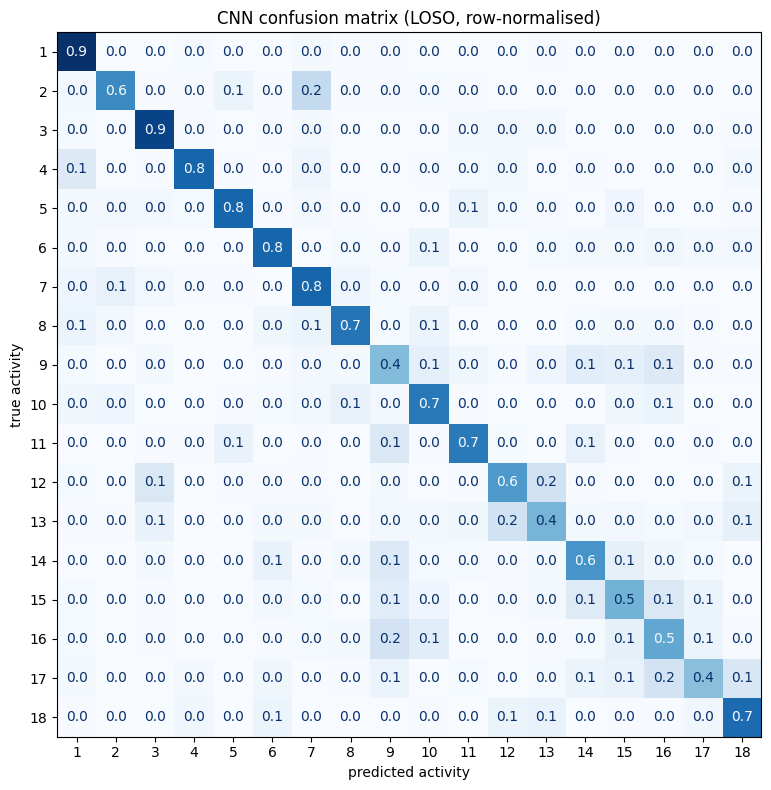

In [8]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, tensorflow as tf, time
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers

SEED = 42
def set_seed(s=SEED):
    np.random.seed(s); tf.random.set_seed(s); tf.keras.utils.set_random_seed(s)
set_seed()
P = Path("data/processed"); R = Path("results"); (R/"figures").mkdir(parents=True, exist_ok=True)
X = np.load(P/"X.npy").astype(np.float32) / 4095.0      # sensor range is 0-4095
y = np.load(P/"y.npy"); subj = np.load(P/"subject.npy")
print("GPU:", tf.config.list_physical_devices("GPU"))

def build_cnn(seq_len=208, n_feat=200, n_classes=18):
    inp = tf.keras.Input(shape=(seq_len, n_feat))
    x = layers.Conv1D(64, 5, padding="same")(inp);  x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 5, padding="same")(x);   x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 3, padding="same", name="last_conv")(x); x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = tf.keras.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def train_predict(tr, te, max_epochs=60):
    set_seed()
    tr_in, va = train_test_split(tr, test_size=0.1, stratify=y[tr], random_state=SEED)   # validation comes from the training part only
    m = build_cnn()
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    h = m.fit(X[tr_in], y[tr_in], validation_data=(X[va], y[va]), epochs=max_epochs, batch_size=32, callbacks=[es], verbose=0)
    return m.predict(X[te], verbose=0).argmax(1), len(h.history["loss"])

# Leave-one-subject-out: train on 13 people, test on the 14th, repeat for everyone
preds = np.full(len(y), -1); rows = []
for k, (tr, te) in enumerate(LeaveOneGroupOut().split(X, y, groups=subj), 1):
    t = time.time(); p, ep = train_predict(tr, te); preds[te] = p
    acc = accuracy_score(y[te], p); rows.append([int(subj[te][0]), round(acc, 4), ep])
    print(f"held-out subject {int(subj[te][0]):2d}: acc={acc:.4f}  epochs={ep}  ({time.time()-t:.0f}s)")

# Summary and saving
print(f"\nCNN LOSO: acc={accuracy_score(y, preds):.4f}  macroF1={f1_score(y, preds, average='macro'):.4f}")
df = pd.DataFrame(rows, columns=["held_out_subject", "accuracy", "epochs"])
print(f"per-subject accuracy: mean={df.accuracy.mean():.3f}  min={df.accuracy.min():.3f}  max={df.accuracy.max():.3f}")
df.to_csv(R/"cnn_loso_per_subject.csv", index=False); np.save(R/"cnn_loso_preds.npy", preds)

cm = confusion_matrix(y, preds, labels=range(18), normalize="true")
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=range(1, 19)).plot(ax=ax, cmap="Blues", colorbar=False, values_format=".1f")
ax.set(title="CNN confusion matrix (LOSO, row-normalised)", xlabel="predicted activity", ylabel="true activity")
plt.tight_layout(); plt.savefig(R/"figures"/"cnn_loso_confusion.png", dpi=120); plt.show()

In [9]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, tensorflow as tf, time
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score
from tensorflow.keras import layers

SEED = 42
def set_seed(s=SEED):
    np.random.seed(s); tf.random.set_seed(s); tf.keras.utils.set_random_seed(s)
set_seed()
P = Path("data/processed"); R = Path("results"); R.mkdir(exist_ok=True)
X = np.load(P/"X.npy").astype(np.float32) / 4095.0
y = np.load(P/"y.npy"); L = np.minimum(np.load(P/"lengths.npy"), 208)   # true (unpadded) length of each trial

def build_cnn(seq_len=208, n_feat=200, n_classes=18):
    inp = tf.keras.Input(shape=(seq_len, n_feat))
    x = layers.Conv1D(64, 5, padding="same")(inp);  x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 5, padding="same")(x);   x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 3, padding="same", name="last_conv")(x); x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling1D()(x); x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = tf.keras.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def train_model(tr):
    set_seed()
    tr_in, va = train_test_split(tr, test_size=0.1, stratify=y[tr], random_state=SEED)
    m = build_cnn()
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    m.fit(X[tr_in], y[tr_in], validation_data=(X[va], y[va]), epochs=60, batch_size=32, callbacks=[es], verbose=0)
    return m

def shuffle_time(Xs, Ls, seed=SEED):          # same frames, random order (padding stays at the end)
    rng = np.random.default_rng(seed); out = Xs.copy()
    for i in range(len(Xs)): out[i, :Ls[i]] = Xs[i, :Ls[i]][rng.permutation(Ls[i])]
    return out

def mean_frame(Xs, Ls):                       # every frame replaced by the trial's average frame
    out = np.zeros_like(Xs)
    for i in range(len(Xs)): out[i, :Ls[i]] = Xs[i, :Ls[i]].mean(axis=0)
    return out

rows = []
for k, (tr, te) in enumerate(StratifiedKFold(10, shuffle=True, random_state=SEED).split(X, y), 1):
    m = train_model(tr)
    acc = lambda Xt: accuracy_score(y[te], m.predict(Xt, verbose=0).argmax(1))
    a0, a1, a2 = acc(X[te]), acc(shuffle_time(X[te], L[te])), acc(mean_frame(X[te], L[te]))
    rows.append([k, a0, a1, a2]); print(f"fold {k:2d}: original={a0:.4f}  frames shuffled={a1:.4f}  mean frame only={a2:.4f}")

df = pd.DataFrame(rows, columns=["fold", "original", "shuffled", "mean_frame"])
print("\nMEAN over folds:"); print(df[["original", "shuffled", "mean_frame"]].mean().round(4).to_string())
df.to_csv(R/"time_ablation.csv", index=False)

fold  1: original=0.7619  frames shuffled=0.7619  mean frame only=0.7619
fold  2: original=0.7222  frames shuffled=0.7222  mean frame only=0.7222
fold  3: original=0.7619  frames shuffled=0.7659  mean frame only=0.7698
fold  4: original=0.7222  frames shuffled=0.7143  mean frame only=0.7183
fold  5: original=0.7302  frames shuffled=0.7302  mean frame only=0.7302
fold  6: original=0.7421  frames shuffled=0.7381  mean frame only=0.7381
fold  7: original=0.7381  frames shuffled=0.7381  mean frame only=0.7381
fold  8: original=0.7540  frames shuffled=0.7540  mean frame only=0.7579
fold  9: original=0.7659  frames shuffled=0.7659  mean frame only=0.7698
fold 10: original=0.7024  frames shuffled=0.7063  mean frame only=0.7024

MEAN over folds:
original      0.7401
shuffled      0.7397
mean_frame    0.7409


model test accuracy: 0.7262  (n=504)
IG completeness check, mean |gap|: 0.0014 (should be small)
correlation between IG importance and mean pressure, per activity: [0.65 0.79 0.89 0.81 0.88 0.86 0.65 0.71 0.89 0.88 0.79 0.81 0.97 0.91
 0.84 0.76 0.83 0.84]
average correlation: 0.82


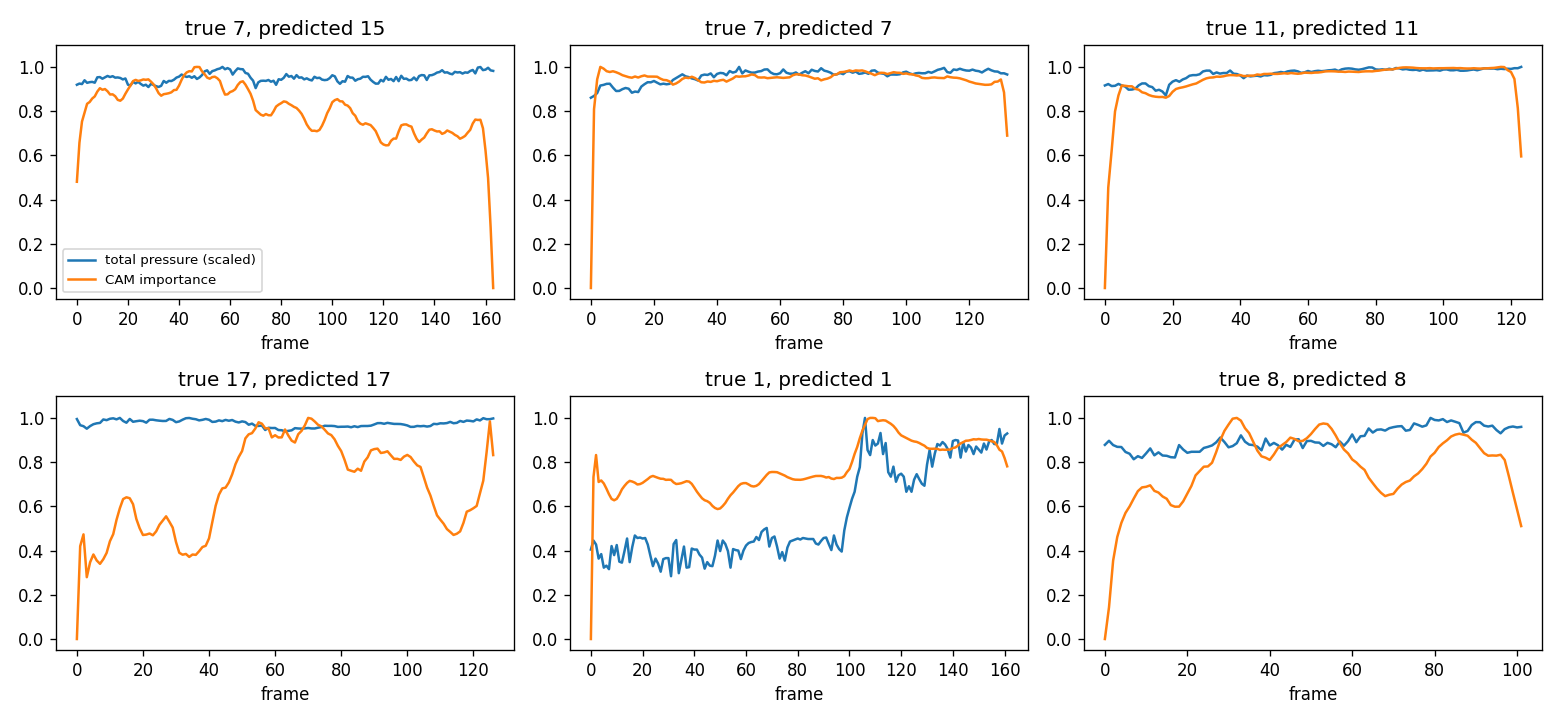

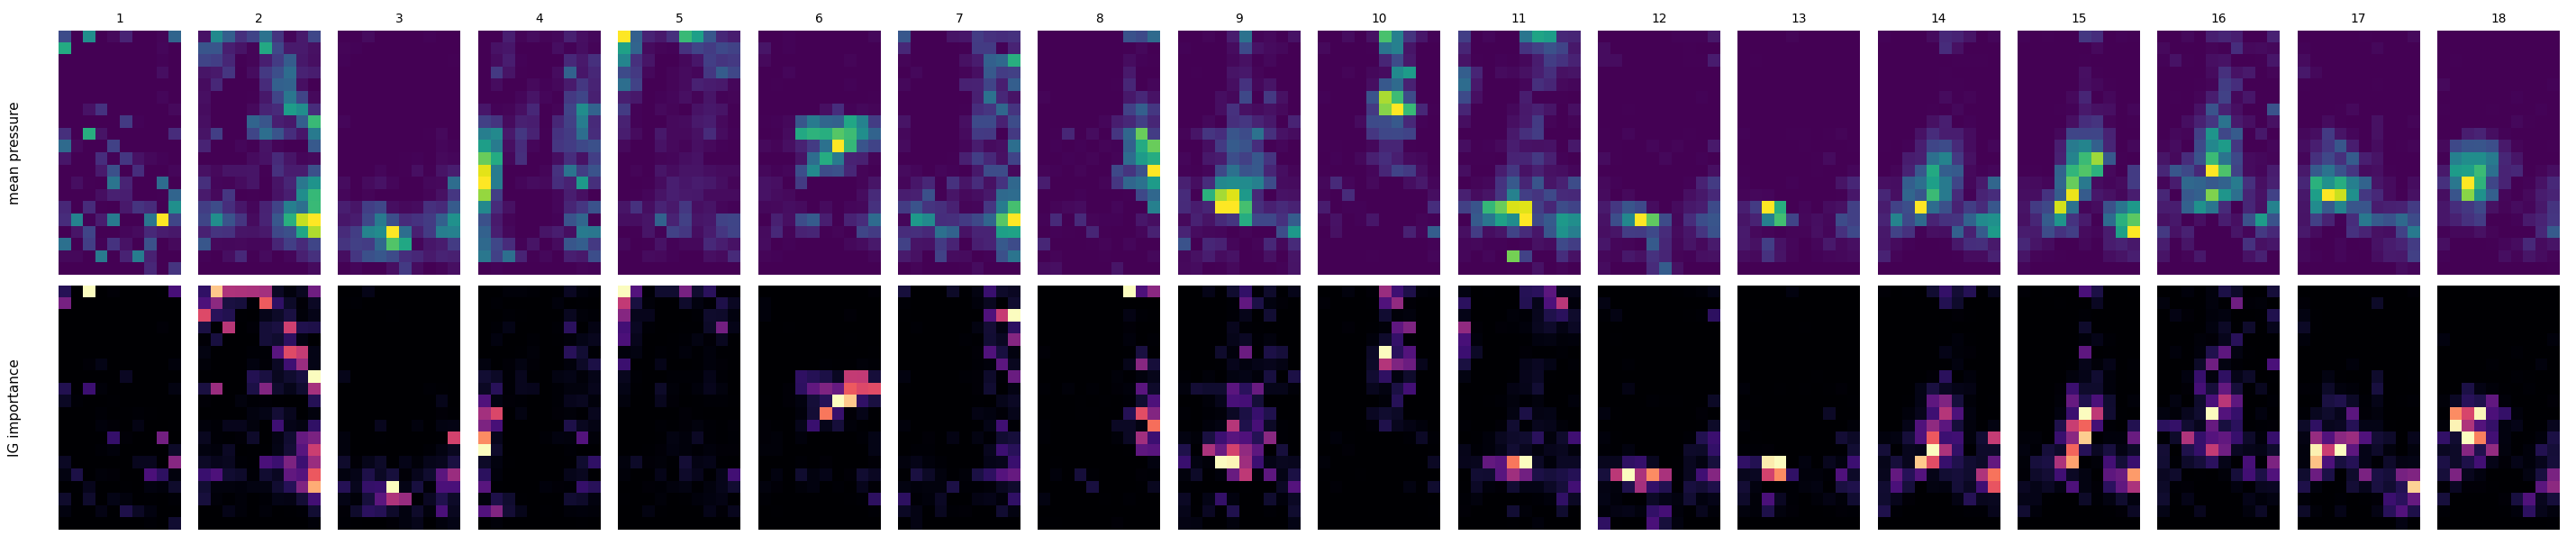

In [10]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from tensorflow.keras import layers
from IPython.display import Image, display

SEED = 42
def set_seed(s=SEED):
    np.random.seed(s); tf.random.set_seed(s); tf.keras.utils.set_random_seed(s)
set_seed()
P = Path("data/processed"); R = Path("results"); (R/"figures").mkdir(parents=True, exist_ok=True)
X = np.load(P/"X.npy").astype(np.float32) / 4095.0
y = np.load(P/"y.npy"); L = np.minimum(np.load(P/"lengths.npy"), 208)

def build_cnn(seq_len=208, n_feat=200, n_classes=18):
    inp = tf.keras.Input(shape=(seq_len, n_feat))
    x = layers.Conv1D(64, 5, padding="same")(inp);  x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 5, padding="same")(x);   x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 3, padding="same", name="last_conv")(x); x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling1D()(x); x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = tf.keras.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

# ---- train one model on 80% of the data, keep 20% for explanations ----
tr, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)
tr_in, va = train_test_split(tr, test_size=0.1, stratify=y[tr], random_state=SEED)
set_seed(); model = build_cnn()
es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
model.fit(X[tr_in], y[tr_in], validation_data=(X[va], y[va]), epochs=60, batch_size=32, callbacks=[es], verbose=0)
pred = model.predict(X[te], verbose=0).argmax(1)
print(f"model test accuracy: {accuracy_score(y[te], pred):.4f}  (n={len(te)})")

# ---- CAM (Wang et al., 2017): importance of each time step for a class ----
gap = [l for l in model.layers if isinstance(l, layers.GlobalAveragePooling1D)][0]
fmap_model = tf.keras.Model(model.input, gap.input)          # feature maps just before pooling
W = model.layers[-1].get_weights()[0]                        # dense weights (128 x 18)
def cam(x, cls, n):
    f = fmap_model.predict(x[None], verbose=0)[0]
    c = f[:n] @ W[:, cls]
    return (c - c.min()) / (c.max() - c.min() + 1e-8)

# ---- Integrated Gradients: importance of each (time step, sensor) ----
def integrated_gradients(x, cls, steps=50):
    x = tf.constant(x[None]); base = tf.zeros_like(x)        # baseline = no pressure
    alphas = tf.reshape(tf.linspace(0.0, 1.0, steps + 1), (-1, 1, 1))
    inter = base + alphas * (x - base)
    with tf.GradientTape() as tape:
        tape.watch(inter); p = model(inter, training=False)[:, cls]
    g = tape.gradient(p, inter)
    g = (g[:-1] + g[1:]) / 2.0
    attr = ((x - base)[0] * tf.reduce_mean(g, axis=0)).numpy()
    gap_ = float(model(x, training=False)[0, cls] - model(base, training=False)[0, cls]) - attr.sum()
    return attr, gap_

# ---- Figure 1: CAM next to the pressure signal ----
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, i in zip(axes.ravel(), te[:6]):
    n = L[i]; c = int(pred[list(te).index(i)])
    ax.plot(X[i, :n].sum(1) / X[i, :n].sum(1).max(), label="total pressure (scaled)")
    ax.plot(cam(X[i], c, n), label="CAM importance")
    ax.set(title=f"true {y[i]+1}, predicted {c+1}", xlabel="frame", ylim=(-0.05, 1.1))
axes[0, 0].legend(fontsize=8); plt.tight_layout(); plt.savefig(R/"figures"/"xai_cam_examples.png", dpi=120); plt.close()

# ---- Figure 2: IG sleeve heatmaps per activity vs. the mean pressure pattern ----
fig, axes = plt.subplots(2, 18, figsize=(26, 5.5)); corr, gaps = [], []
for c in range(18):
    idx = [i for i, p in zip(te, pred) if y[i] == c and p == c][:8]       # correctly classified test trials
    if not idx: continue
    A, M = [], []
    for i in idx:
        a, g_ = integrated_gradients(X[i], c); gaps.append(abs(g_))
        A.append(np.abs(a[:L[i]]).mean(0)); M.append(X[i, :L[i]].mean(0))
    A, M = np.mean(A, 0), np.mean(M, 0)
    axes[0, c].imshow(M.reshape(20, 10), cmap="viridis"); axes[0, c].set_title(f"{c+1}", fontsize=9); axes[0, c].axis("off")
    axes[1, c].imshow(A.reshape(20, 10), cmap="magma"); axes[1, c].axis("off")
    corr.append(np.corrcoef(A, M)[0, 1])
axes[0, 0].text(-0.3, 0.5, "mean pressure", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.3, 0.5, "IG importance", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.savefig(R/"figures"/"xai_ig_sleeve_heatmaps.png", dpi=110); plt.close()
print(f"IG completeness check, mean |gap|: {np.mean(gaps):.4f} (should be small)")
print("correlation between IG importance and mean pressure, per activity:", np.round(corr, 2))
print("average correlation: %.2f" % np.mean(corr))
display(Image(str(R/"figures"/"xai_cam_examples.png"))); display(Image(str(R/"figures"/"xai_ig_sleeve_heatmaps.png")))

 percent_removed     IG  highest_pressure  random
               0 0.7262            0.7262  0.7262
               5 0.1766            0.2302  0.7123
              10 0.0813            0.0933  0.6865
              20 0.0556            0.0575  0.6468
              30 0.0556            0.0556  0.5880
              50 0.0556            0.0556  0.4702
              70 0.0556            0.0556  0.2903

AUC (lower = better):  IG=0.091   highest-pressure=0.096   random=0.545


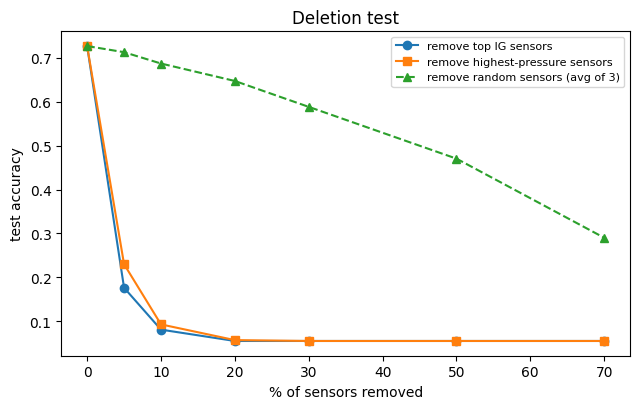

In [11]:
import pandas as pd
K = [0, 5, 10, 20, 30, 50, 70]                     # % of the 200 sensors removed

# per-sample sensor importance (IG for the class the model predicted) and sensor pressure
sens_ig = np.zeros((len(te), 200)); sens_pr = np.zeros((len(te), 200))
for j, i in enumerate(te):
    a, _ = integrated_gradients(X[i], int(pred[j]))
    sens_ig[j] = np.abs(a[:L[i]]).mean(0)
    sens_pr[j] = X[i, :L[i]].mean(0)

def drop_curve(sens):
    accs = []
    for k in K:
        n = int(round(200 * k / 100)); Xm = X[te].copy()
        if n > 0:
            top = np.argsort(-sens, axis=1)[:, :n]          # the n most important sensors for each sample
            for j in range(len(te)): Xm[j][:, top[j]] = 0.0  # remove them (set pressure to 0)
        accs.append(accuracy_score(y[te], model.predict(Xm, verbose=0).argmax(1)))
    return np.array(accs)

curve_ig, curve_pr = drop_curve(sens_ig), drop_curve(sens_pr)
curve_rand = np.mean([drop_curve(np.random.default_rng(s).random((len(te), 200))) for s in range(3)], axis=0)

def auc(c):                                         # area under the accuracy curve (lower = bigger drop = more faithful)
    k = np.array(K, float); return float(((c[:-1] + c[1:]) / 2 * np.diff(k)).sum() / (k[-1] - k[0]))

res = pd.DataFrame({"percent_removed": K, "IG": curve_ig, "highest_pressure": curve_pr, "random": curve_rand}).round(4)
print(res.to_string(index=False))
print(f"\nAUC (lower = better):  IG={auc(curve_ig):.3f}   highest-pressure={auc(curve_pr):.3f}   random={auc(curve_rand):.3f}")
res.to_csv(R/"xai_faithfulness_deletion.csv", index=False)

plt.figure(figsize=(6.5, 4.2))
plt.plot(K, curve_ig, "o-", label="remove top IG sensors"); plt.plot(K, curve_pr, "s-", label="remove highest-pressure sensors")
plt.plot(K, curve_rand, "^--", label="remove random sensors (avg of 3)")
plt.xlabel("% of sensors removed"); plt.ylabel("test accuracy"); plt.title("Deletion test"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(R/"figures"/"xai_faithfulness_deletion.png", dpi=120); plt.show()


=== DELETE test ===
 percent     IG  highest_pressure  random
       0 0.7262            0.7262  0.7262
       1 0.5437            0.5873  0.7269
       2 0.4524            0.4881  0.7255
       3 0.3671            0.4107  0.7262
       5 0.2738            0.3175  0.7103
       7 0.2282            0.2480  0.6951
      10 0.1984            0.2163  0.6799
      15 0.1885            0.1905  0.6415
      20 0.1984            0.1964  0.5972
AUC: IG=0.263  highest-pressure=0.281  random=0.674

=== INSERT test ===
 percent     IG  highest_pressure  random
       0 0.0556            0.0556  0.0556
       1 0.1825            0.1647  0.0575
       2 0.2302            0.2262  0.0595
       3 0.2758            0.2520  0.0642
       5 0.2897            0.2996  0.0668
       7 0.3155            0.3175  0.0734
      10 0.3214            0.3234  0.0820
      15 0.3452            0.3333  0.1065
      20 0.3452            0.3433  0.1270
AUC: IG=0.305  highest-pressure=0.300  random=0.087


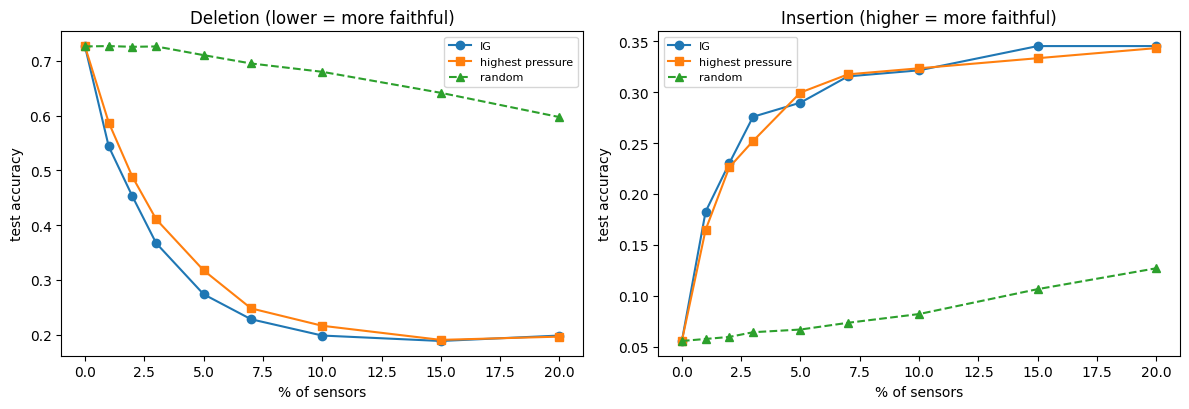

In [12]:
K2 = [0, 1, 2, 3, 5, 7, 10, 15, 20]                                      # % of sensors
base = np.mean([X[i, :L[i]].mean(0) for i in tr_in], axis=0)              # typical pressure of each sensor (200,)

def make(Xo, Lo, sens, k, mode):
    n = int(round(200 * k / 100)); Xm = Xo.copy()
    top = np.argsort(-sens, axis=1)[:, :n]
    for j in range(len(Xo)):
        if mode == "delete":
            if n > 0: Xm[j, :Lo[j]][:, top[j]] = base[top[j]]             # replace top sensors by typical pressure
        else:
            Xm[j, :Lo[j]] = base                                          # blank input (typical pressure everywhere)
            if n > 0: Xm[j, :Lo[j]][:, top[j]] = Xo[j, :Lo[j]][:, top[j]]    # put the top sensors back
    return Xm

def curve(sens, mode):
    return np.array([accuracy_score(y[te], model.predict(make(X[te], L[te], sens, k, mode), verbose=0).argmax(1)) for k in K2])

def auc2(c):
    k = np.array(K2, float); return float(((c[:-1] + c[1:]) / 2 * np.diff(k)).sum() / (k[-1] - k[0]))

out = {}
for mode in ["delete", "insert"]:
    c_ig, c_pr = curve(sens_ig, mode), curve(sens_pr, mode)
    c_rd = np.mean([curve(np.random.default_rng(s).random((len(te), 200)), mode) for s in range(3)], axis=0)
    out[mode] = (c_ig, c_pr, c_rd)
    t = pd.DataFrame({"percent": K2, "IG": c_ig, "highest_pressure": c_pr, "random": c_rd}).round(4)
    print(f"\n=== {mode.upper()} test ==="); print(t.to_string(index=False))
    print(f"AUC: IG={auc2(c_ig):.3f}  highest-pressure={auc2(c_pr):.3f}  random={auc2(c_rd):.3f}")
    t.to_csv(R/f"xai_faithfulness_{mode}_v2.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, mode, ttl in zip(axes, ["delete", "insert"], ["Deletion (lower = more faithful)", "Insertion (higher = more faithful)"]):
    c_ig, c_pr, c_rd = out[mode]
    ax.plot(K2, c_ig, "o-", label="IG"); ax.plot(K2, c_pr, "s-", label="highest pressure"); ax.plot(K2, c_rd, "^--", label="random")
    ax.set(title=ttl, xlabel="% of sensors", ylabel="test accuracy"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(R/"figures"/"xai_faithfulness_v2.png", dpi=120); plt.show()

model test accuracy: 0.6964
first trial took 8s -> estimated total 19.5 min
TSR + IG computed for 150 trials in 15.1 min
mean Spearman rank correlation of sensor importance:  TSR vs pressure=0.74  TSR vs IG=0.74  IG vs pressure=0.99
  test   TSR    IG  pressure  random
delete 0.279 0.277     0.294   0.598
insert 0.288 0.296     0.290   0.108


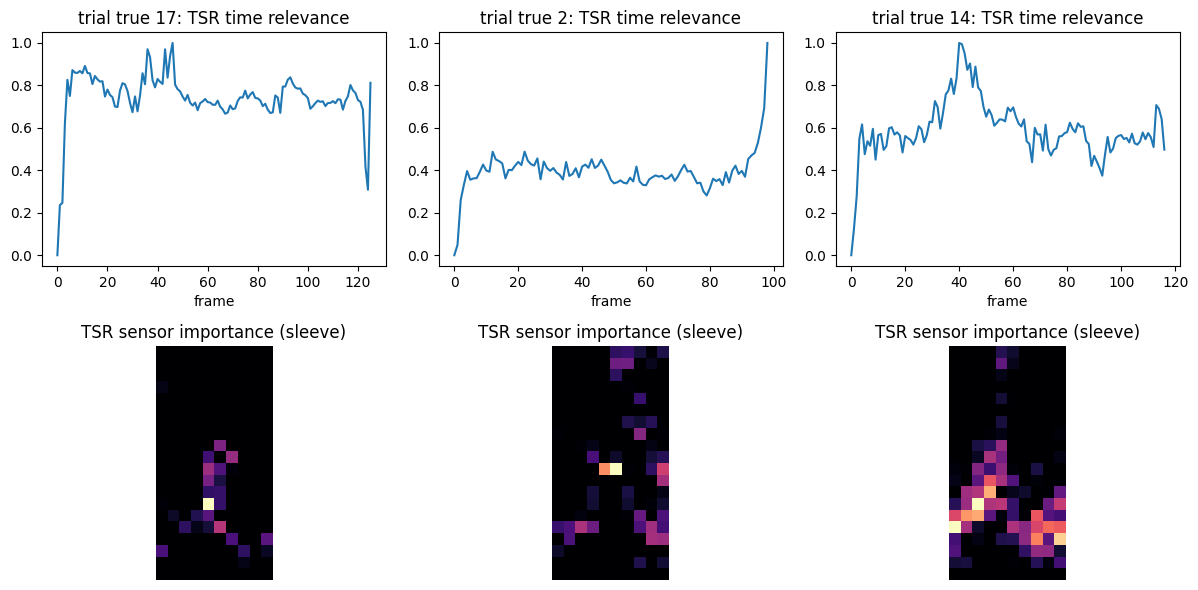

In [13]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, tensorflow as tf, time
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from tensorflow.keras import layers

SEED, EPOCHS, N_EVAL = 1, 60, 150
def set_seed(s):
    np.random.seed(s); tf.random.set_seed(s); tf.keras.utils.set_random_seed(s)
set_seed(SEED)
P = Path("data/processed"); R = Path("results"); (R/"figures").mkdir(parents=True, exist_ok=True)
X = np.load(P/"X.npy").astype(np.float32) / 4095.0
y = np.load(P/"y.npy"); L = np.minimum(np.load(P/"lengths.npy"), 208)
K2 = [0, 1, 2, 3, 5, 7, 10, 15, 20]

def build_cnn(seq_len=208, n_feat=200, n_classes=18):
    inp = tf.keras.Input(shape=(seq_len, n_feat))
    x = layers.Conv1D(64, 5, padding="same")(inp);  x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 5, padding="same")(x);   x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 3, padding="same", name="last_conv")(x); x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling1D()(x); x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = tf.keras.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

tr, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)
tr_in, va = train_test_split(tr, test_size=0.1, stratify=y[tr], random_state=SEED)
model = build_cnn()
es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
model.fit(X[tr_in], y[tr_in], validation_data=(X[va], y[va]), epochs=EPOCHS, batch_size=32, callbacks=[es], verbose=0)
pred_all = model.predict(X[te], verbose=0).argmax(1)
print(f"model test accuracy: {accuracy_score(y[te], pred_all):.4f}")
base = np.mean([X[i, :L[i]].mean(0) for i in tr_in], axis=0)

# ---------------- gradient saliency (batched) ----------------
@tf.function(reduce_retracing=True)
def grad_batch(xb, cls):
    with tf.GradientTape() as tape:
        tape.watch(xb); p = tf.gather(model(xb, training=False), cls, axis=1)
    return tape.gradient(p, xb)
def saliency(xb, cls):
    out = [grad_batch(tf.constant(xb[i:i+200]), tf.constant(cls, tf.int32)).numpy() for i in range(0, len(xb), 200)]
    return np.concatenate(out)
def mm(v): return (v - v.min()) / (v.max() - v.min() + 1e-12)

# ---------------- Temporal Saliency Rescaling (Ismail et al., 2020), batched re-implementation ----------------
def tsr(x, cls, n, quantile=0.55):
    """x: (208,200) one trial, n: its true number of frames. Returns (time_relevance (n,), tsr_map (n,200))."""
    S = saliency(x[None], cls)[0]                                   # saliency of the original input
    Xt = np.repeat(x[None], n, 0); Xt[np.arange(n), np.arange(n), :] = 0.0     # blank out one time step at a time
    St = saliency(Xt, cls)
    t_rel = mm(np.abs(S[None] - St).reshape(n, -1).sum(1))          # how much each time step changes the saliency
    thr = np.quantile(t_rel, quantile)
    out = np.zeros((n, 200), dtype=np.float32)
    for t in range(n):
        if t_rel[t] > thr:                                          # relevant moments only: blank out one sensor at a time
            Xc = np.repeat(x[None], 200, 0); Xc[np.arange(200), t, np.arange(200)] = 0.0
            f_rel = mm(np.abs(S[None] - saliency(Xc, cls)).reshape(200, -1).sum(1))
        else:
            f_rel = np.full(200, 0.1, dtype=np.float32)
        out[t] = t_rel[t] * f_rel
    return t_rel, out

# ---------------- Integrated Gradients (for comparison) ----------------
def ig(x, cls, steps=50):
    x = tf.constant(x[None]); b = tf.zeros_like(x)
    a = tf.reshape(tf.linspace(0.0, 1.0, steps + 1), (-1, 1, 1)); inter = b + a * (x - b)
    with tf.GradientTape() as tape:
        tape.watch(inter); p = model(inter, training=False)[:, cls]
    g = tape.gradient(p, inter); g = (g[:-1] + g[1:]) / 2.0
    return ((x - b)[0] * tf.reduce_mean(g, axis=0)).numpy()

# ---------------- run on N_EVAL test trials ----------------
ts = te[:N_EVAL]; pred = pred_all[:N_EVAL]
sens_tsr = np.zeros((len(ts), 200)); sens_ig = np.zeros((len(ts), 200)); sens_pr = np.zeros((len(ts), 200)); t_curves = []
t0 = time.time()
for j, i in enumerate(ts):
    n = int(L[i]); tr_, map_ = tsr(X[i], int(pred[j]), n)
    sens_tsr[j] = map_.mean(0); t_curves.append(tr_)
    sens_ig[j] = np.abs(ig(X[i], int(pred[j]))[:n]).mean(0); sens_pr[j] = X[i, :n].mean(0)
    if j == 0: print(f"first trial took {time.time()-t0:.0f}s -> estimated total {(time.time()-t0)*len(ts)/60:.1f} min")
print(f"TSR + IG computed for {len(ts)} trials in {(time.time()-t0)/60:.1f} min")

def rank_corr(a, b): return np.nanmean([spearmanr(a[j], b[j])[0] for j in range(len(a))])
print(f"mean Spearman rank correlation of sensor importance:  TSR vs pressure={rank_corr(sens_tsr, sens_pr):.2f}  TSR vs IG={rank_corr(sens_tsr, sens_ig):.2f}  IG vs pressure={rank_corr(sens_ig, sens_pr):.2f}")

# ---------------- faithfulness: deletion / insertion on these trials ----------------
def make(sens, k, mode):
    n_ = int(round(200 * k / 100)); Xm = X[ts].copy(); top = np.argsort(-sens, axis=1)[:, :n_]
    for j in range(len(ts)):
        Lj = L[ts][j]
        if mode == "delete":
            if n_ > 0: Xm[j, :Lj][:, top[j]] = base[top[j]]
        else:
            Xm[j, :Lj] = base
            if n_ > 0: Xm[j, :Lj][:, top[j]] = X[ts][j, :Lj][:, top[j]]
    return Xm
def curve(sens, mode): return np.array([accuracy_score(y[ts], model.predict(make(sens, k, mode), verbose=0).argmax(1)) for k in K2])
def auc2(c):
    k = np.array(K2, float); return float(((c[:-1] + c[1:]) / 2 * np.diff(k)).sum() / (k[-1] - k[0]))

rows = []
for mode in ["delete", "insert"]:
    r = {"test": mode}
    for name, s in [("TSR", sens_tsr), ("IG", sens_ig), ("pressure", sens_pr)]: r[name] = auc2(curve(s, mode))
    r["random"] = np.mean([auc2(curve(np.random.default_rng(q).random((len(ts), 200)), mode)) for q in range(2)])
    rows.append(r)
res = pd.DataFrame(rows).round(3); print(res.to_string(index=False)); res.to_csv(R/"xai_tsr_faithfulness.csv", index=False)

# ---------------- figure: when (time relevance) and where (sleeve) for 3 trials ----------------
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for c_, j in enumerate(range(3)):
    axes[0, c_].plot(t_curves[j]); axes[0, c_].set(title=f"trial true {y[ts[j]]+1}: TSR time relevance", xlabel="frame", ylim=(-0.05, 1.05))
    axes[1, c_].imshow(sens_tsr[j].reshape(20, 10), cmap="magma"); axes[1, c_].set_title("TSR sensor importance (sleeve)"); axes[1, c_].axis("off")
plt.tight_layout(); plt.savefig(R/"figures"/"xai_tsr_examples.png", dpi=120); plt.show()

model test accuracy: 0.7063  (n=504)
first trial 0.6s -> estimated total 4.8 min

=== frames replaced by the trial's AVERAGE frame ===
 percent_frames    CAM  TSR_time  highest_pressure_frames  random
              0 0.7063    0.7063                   0.7063  0.7063
             10 0.7103    0.7044                   0.7063  0.7077
             20 0.7044    0.7024                   0.7063  0.7063
             30 0.7024    0.7024                   0.7044  0.7070
             50 0.7024    0.7063                   0.7063  0.7070
             70 0.7024    0.7024                   0.7063  0.7070
             90 0.7044    0.7044                   0.7044  0.7070
            100 0.7063    0.7063                   0.7063  0.7063

=== frames replaced by the trial's ZERO (blank) frame ===
 percent_frames    CAM  TSR_time  highest_pressure_frames  random
              0 0.7063    0.7063                   0.7063  0.7063
             10 0.7063    0.7044                   0.7044  0.7044
             2

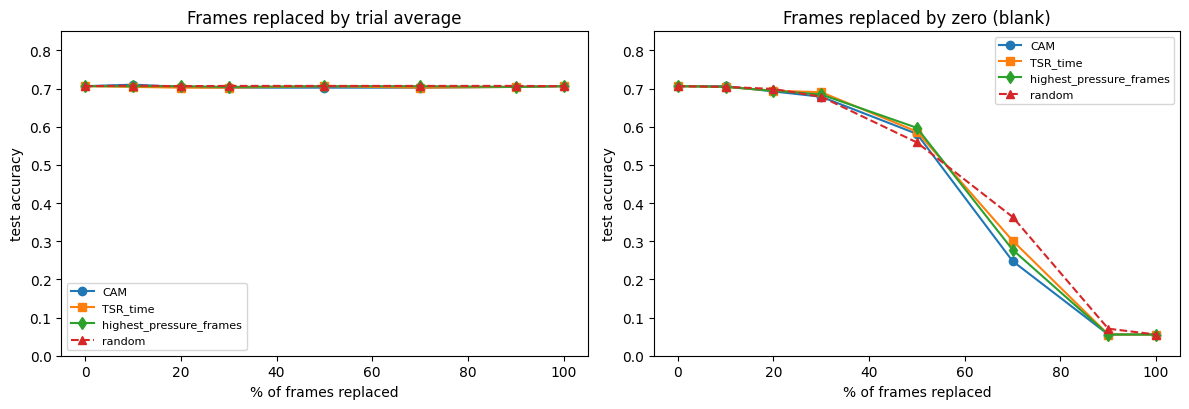

In [14]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, tensorflow as tf, time
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from tensorflow.keras import layers

SEED, EPOCHS = 1, 60
def set_seed(s):
    np.random.seed(s); tf.random.set_seed(s); tf.keras.utils.set_random_seed(s)
set_seed(SEED)
P = Path("data/processed"); R = Path("results"); (R/"figures").mkdir(parents=True, exist_ok=True)
X = np.load(P/"X.npy").astype(np.float32) / 4095.0
y = np.load(P/"y.npy"); L = np.minimum(np.load(P/"lengths.npy"), 208)
KS = [0, 10, 20, 30, 50, 70, 90, 100]                      # % of a trial's frames that are replaced

def build_cnn(seq_len=208, n_feat=200, n_classes=18):
    inp = tf.keras.Input(shape=(seq_len, n_feat))
    x = layers.Conv1D(64, 5, padding="same")(inp);  x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 5, padding="same")(x);   x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 3, padding="same", name="last_conv")(x); x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling1D()(x); x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = tf.keras.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

tr, te = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)
tr_in, va = train_test_split(tr, test_size=0.1, stratify=y[tr], random_state=SEED)
model = build_cnn()
es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
model.fit(X[tr_in], y[tr_in], validation_data=(X[va], y[va]), epochs=EPOCHS, batch_size=32, callbacks=[es], verbose=0)
pred = model.predict(X[te], verbose=0).argmax(1)
print(f"model test accuracy: {accuracy_score(y[te], pred):.4f}  (n={len(te)})")
Lt = L[te]

# ---- time-step relevance curves for every test trial ----
# CAM (Wang et al., 2017)
gap = [l for l in model.layers if isinstance(l, layers.GlobalAveragePooling1D)][0]
fmap_model = tf.keras.Model(model.input, gap.input); W = model.layers[-1].get_weights()[0]
fmaps = fmap_model.predict(X[te], verbose=0)                              # (N, 208, 128)
cam_all = np.einsum("ntk,nk->nt", fmaps, W[:, pred].T)                    # (N, 208)

# TSR step 1 only (time relevance): how much does blanking frame t change the gradient map?
@tf.function(reduce_retracing=True)
def grad_batch(xb, cls):
    with tf.GradientTape() as tape:
        tape.watch(xb); p = tf.gather(model(xb, training=False), cls, axis=1)
    return tape.gradient(p, xb)
def saliency(xb, cls):
    return np.concatenate([grad_batch(tf.constant(xb[i:i+200]), tf.constant(cls, tf.int32)).numpy() for i in range(0, len(xb), 200)])
t0 = time.time(); tsr_all = np.zeros((len(te), 208))
for j, i in enumerate(te):
    n = int(L[i]); x = X[i]
    S = saliency(x[None], int(pred[j]))[0]
    Xt = np.repeat(x[None], n, 0); Xt[np.arange(n), np.arange(n), :] = 0.0
    tsr_all[j, :n] = np.abs(S[None] - saliency(Xt, int(pred[j]))).reshape(n, -1).sum(1)
    if j == 0: print(f"first trial {time.time()-t0:.1f}s -> estimated total {(time.time()-t0)*len(te)/60:.1f} min")
press_all = np.stack([X[i].sum(1) for i in te])                            # total pressure of each frame

def acc_after(curves, k, mode, rng=None):
    Xm = X[te].copy()
    for j in range(len(te)):
        n = int(Lt[j]); m = int(round(n * k / 100))
        if m == 0: continue
        idx = rng.permutation(n)[:m] if rng is not None else np.argsort(-curves[j, :n])[:m]
        Xm[j, idx] = X[te][j, :n].mean(0) if mode == "mean" else 0.0
    return accuracy_score(y[te], model.predict(Xm, verbose=0).argmax(1))

out = {}
for mode in ["mean", "zero"]:
    rows = []
    for k in KS:
        rows.append({"percent_frames": k,
                     "CAM": acc_after(cam_all, k, mode), "TSR_time": acc_after(tsr_all, k, mode),
                     "highest_pressure_frames": acc_after(press_all, k, mode),
                     "random": np.mean([acc_after(None, k, mode, np.random.default_rng(q)) for q in range(3)])})
    out[mode] = pd.DataFrame(rows).round(4)
    print(f"\n=== frames replaced by the trial's {'AVERAGE frame' if mode=='mean' else 'ZERO (blank) frame'} ==="); print(out[mode].to_string(index=False))
    out[mode].to_csv(R/f"xai_temporal_faithfulness_{mode}.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, mode, ttl in zip(axes, ["mean", "zero"], ["Frames replaced by trial average", "Frames replaced by zero (blank)"]):
    d = out[mode]
    for c_, mk in [("CAM", "o-"), ("TSR_time", "s-"), ("highest_pressure_frames", "d-"), ("random", "^--")]: ax.plot(d.percent_frames, d[c_], mk, label=c_)
    ax.set(title=ttl, xlabel="% of frames replaced", ylabel="test accuracy", ylim=(0, 0.85)); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(R/"figures"/"xai_temporal_faithfulness.png", dpi=120); plt.show()